In [1]:
# Step-1: Load / Create the Fine-tuning Data
# (Not shown on screen — replace this with how your notebook loads the data)
finetuning_data = [
    {"text": "Generative AI models can create text images and code"},
    {"text": "Fine tuning adapts a pretrained model to a specific task"},
    {"text": "Tokenization converts text into numbers the model understands"},
    {"text": "Large language models predict the next token in a sequence"},
    {"text": "Training data quality strongly affects model performance"},
] * 280   # 1400 examples, so the split gives 1260 / 140 like in class

print("Number of examples:", len(finetuning_data))
print(finetuning_data[0])



Number of examples: 1400
{'text': 'Generative AI models can create text images and code'}


In [2]:
# Step-2: Build the Vocabulary
# (Not shown on screen — 0 is kept for unknown words)
all_words = []
for item in finetuning_data:
    all_words.extend(item["text"].split())

unique_words = sorted(set(all_words))
vocabulary = {word: idx + 1 for idx, word in enumerate(unique_words)}

print("Vocabulary size:", len(vocabulary))


Vocabulary size: 37


In [3]:

# Step-3: Tokenize a Single Example
# (Not shown on screen)
sample_text = finetuning_data[0]["text"]
words = sample_text.split()
print("Words:", words)


Words: ['Generative', 'AI', 'models', 'can', 'create', 'text', 'images', 'and', 'code']


In [4]:

# Step-4: Convert Words to Token IDs
# (Not shown on screen)
token_ids = [vocabulary.get(word, 0) for word in words]
print("Token IDs:", token_ids)


Token IDs: [3, 1, 21, 11, 14, 32, 16, 10, 12]


In [5]:

# Step-5: Handle long Sequences
max_length = 50
token_ids = token_ids[:max_length]

print("Number of tokens after truncation:", len(token_ids))
print(token_ids)


Number of tokens after truncation: 9
[3, 1, 21, 11, 14, 32, 16, 10, 12]


In [6]:

# Step-6: Tokenize the Entire Dataset
all_tokenized_data = []
for item in finetuning_data:
    words = item["text"].split()
    ids = [vocabulary.get(word, 0) for word in words]
    ids = ids[:max_length]
    all_tokenized_data.append(ids)

print("Number of tokenized examples:", len(all_tokenized_data))
print("First example:")
print(all_tokenized_data[0])


Number of tokenized examples: 1400
First example:
[3, 1, 21, 11, 14, 32, 16, 10, 12]


In [7]:

# Step-7: Add Labels
labels = all_tokenized_data.copy()
print("Input IDs:")
print(all_tokenized_data[0])

print("\nLabels:")
print(labels[0])


Input IDs:
[3, 1, 21, 11, 14, 32, 16, 10, 12]

Labels:
[3, 1, 21, 11, 14, 32, 16, 10, 12]


In [8]:

# Step-8: Prepare Train/Test Splits
split_point = int(len(all_tokenized_data) * 0.9)

train_data = all_tokenized_data[:split_point]
test_data = all_tokenized_data[split_point:]

print("training:", len(train_data))
print("testing:", len(test_data))

training: 1260
testing: 140


In [9]:
# Step-9: Load the Gemini API Key
# pip install google-genai python-dotenv
import os
from dotenv import load_dotenv, find_dotenv
from google import genai

_ = load_dotenv(find_dotenv())
client = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))

print("API key loaded")

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


API key loaded


In [11]:
response = client.models.generate_content(
    model="gemini-3.6-flash",
    contents="Say hello in one line"
)
print(response.text)

Hello! How can I help you today?


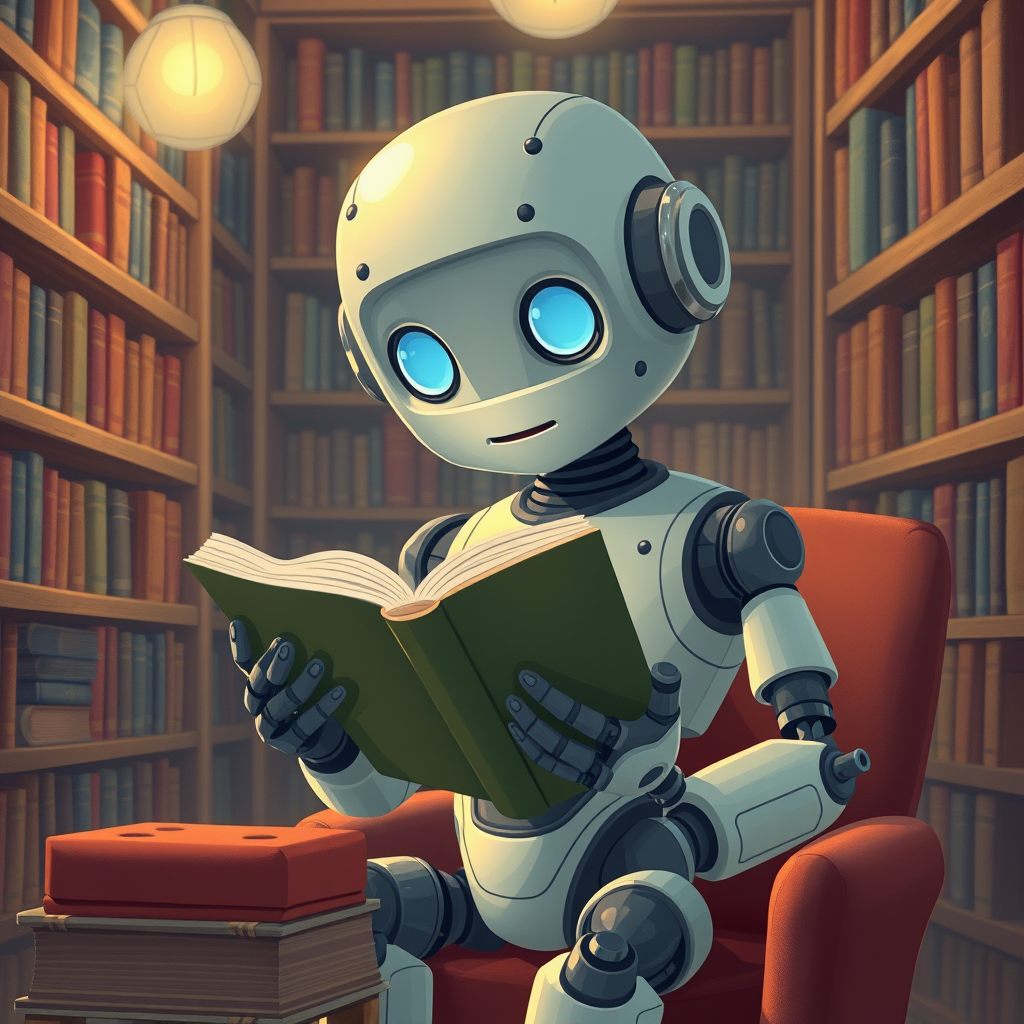

Image saved as generated_image.png


In [14]:
# Step-10: Generate an Image from Text
# Gemini image models have 0 free-tier quota (429 RESOURCE_EXHAUSTED),
# so we use the free Hugging Face Inference API with FLUX.1-schnell instead.
# pip install huggingface_hub pillow
from huggingface_hub import InferenceClient

hf_client = InferenceClient(token=os.getenv("HUGGINGFACEHUB_API_TOKEN"))

Text_PROMPT = "A cute robot reading a book in a cozy library, digital art"

image = hf_client.text_to_image(Text_PROMPT, model="black-forest-labs/FLUX.1-schnell")
image.save("generated_image.png")
display(image)
print("Image saved as generated_image.png")